In [14]:
# CELL 1: ENVIRONMENT SETUP & DETERMINISTIC SEEDS
# Imports core libraries: PyTorch, NumPy, Matplotlib, and Scikit-Learn.
# Enforces strict seed determinism across CPU and CUDA for reproducible benchmark runs.

import os
import sys
import time
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(42)
print("Environment initialized with deterministic seed 42.")

Environment initialized with deterministic seed 42.


In [15]:
# CELL 2: CORA DATASET LOADER & GRAPH METRICS
# Loads Cora from disk cache or generates benchmark Cora graph matching real distributions.
# Computes node count, directed edge count, feature dimensions, class distribution, and homophily ratio.

CORA_CLASSES = {
    0: "Case_Based",
    1: "Genetic_Algorithms",
    2: "Neural_Networks",
    3: "Probabilistic_Methods",
    4: "Reinforcement_Learning",
    5: "Rule_Learning",
    6: "Theory",
}


def load_cora():
    """Loads the real Cora citation dataset via Planetoid or local disk cache."""
    cache_path = "./data/cora/cora_cache.pt"
    if os.path.exists(cache_path):
        print(f"Loading Cora from disk cache: {cache_path}")
        return torch.load(cache_path, weights_only=False)

    try:
        from torch_geometric.datasets import Planetoid
    except ImportError:
        import subprocess
        import sys
        print("torch_geometric not found in this environment. Installing now for Colab...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "torch_geometric"])
        from torch_geometric.datasets import Planetoid

    print("Downloading and loading Cora benchmark dataset via PyTorch Geometric...")
    dataset = Planetoid(root="./data/Cora", name="Cora")
    data_obj = dataset[0]

    data = {
        "x": data_obj.x,
        "edge_index": data_obj.edge_index,
        "y": data_obj.y,
        "train_mask": data_obj.train_mask,
        "val_mask": data_obj.val_mask,
        "test_mask": data_obj.test_mask,
        "num_nodes": data_obj.num_nodes,
        "num_edges": data_obj.edge_index.size(1),
        "num_features": dataset.num_features,
        "num_classes": dataset.num_classes,
        "class_names": CORA_CLASSES,
    }
    os.makedirs(os.path.dirname(cache_path), exist_ok=True)
    torch.save(data, cache_path)
    return data


data = load_cora()
edge_index = data["edge_index"]
num_nodes = data["num_nodes"]
num_edges = data["num_edges"]
y_labels = data["y"]

# Compute edge homophily
u_classes = y_labels[edge_index[0]]
v_classes = y_labels[edge_index[1]]
homophily = (u_classes == v_classes).float().mean().item()

print(f"Dataset Loaded Successfully:")
print(f"  Nodes: {num_nodes} | Directed Edges: {num_edges} | Features: {data['num_features']} | Classes: {data['num_classes']}")
print(f"  Graph Edge Homophily Ratio: {homophily:.4f} ({homophily * 100:.1f}% intra-class edges)")
print(f"  Splits -> Train: {data['train_mask'].sum().item()} | Val: {data['val_mask'].sum().item()} | Test: {data['test_mask'].sum().item()}")



Loading Cora from disk cache: ./data/cora/cora_cache.pt
Dataset Loaded Successfully:
  Nodes: 2708 | Directed Edges: 10556 | Features: 1433 | Classes: 7
  Graph Edge Homophily Ratio: 0.8100 (81.0% intra-class edges)
  Splits -> Train: 140 | Val: 500 | Test: 1000


In [16]:
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
print("Using ready-made PyTorch Geometric layers: GCNConv, SAGEConv, GATConv.")


class MLP(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, num_layers: int = 2, dropout: float = 0.5):
        super().__init__()
        self.convs = nn.ModuleList()
        self.convs.append(nn.Linear(in_dim, hidden_dim))
        for _ in range(num_layers - 2):
            self.convs.append(nn.Linear(hidden_dim, hidden_dim))
        self.convs.append(nn.Linear(hidden_dim, out_dim))
        self.dropout = dropout

    def forward(self, x, edge_index=None):
        for fc in self.convs[:-1]:
            x = F.relu(fc(x))
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.convs[-1](x)

    def get_embeddings(self, x, edge_index=None):
        for fc in self.convs[:-1]:
            x = F.relu(fc(x))
        return x


class GCN(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, num_layers: int = 2, dropout: float = 0.5):
        super().__init__()
        self.num_layers = num_layers
        self.dropout = dropout
        self.convs = nn.ModuleList()
        self.convs.append(GCNConv(in_dim, hidden_dim))
        for _ in range(num_layers - 2):
            self.convs.append(GCNConv(hidden_dim, hidden_dim))
        self.convs.append(GCNConv(hidden_dim, out_dim))

    def forward(self, x, edge_index):
        for conv in self.convs[:-1]:
            x = conv(x, edge_index)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.convs[-1](x, edge_index)

    def get_embeddings(self, x, edge_index):
        for conv in self.convs[:-1]:
            x = conv(x, edge_index)
            x = F.relu(x)
        return x


class GraphSAGE(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, num_layers: int = 2, dropout: float = 0.5):
        super().__init__()
        self.num_layers = num_layers
        self.dropout = dropout
        self.convs = nn.ModuleList()
        self.convs.append(SAGEConv(in_dim, hidden_dim, aggr="mean"))
        for _ in range(num_layers - 2):
            self.convs.append(SAGEConv(hidden_dim, hidden_dim, aggr="mean"))
        self.convs.append(SAGEConv(hidden_dim, out_dim, aggr="mean"))

    def forward(self, x, edge_index):
        for conv in self.convs[:-1]:
            x = conv(x, edge_index)
            x = F.relu(x)
            x = F.dropout(x, p=self.dropout, training=self.training)
        return self.convs[-1](x, edge_index)

    def get_embeddings(self, x, edge_index):
        for conv in self.convs[:-1]:
            x = conv(x, edge_index)
            x = F.relu(x)
        return x


class GAT(nn.Module):
    def __init__(self, in_dim: int, hidden_dim: int, out_dim: int, heads: int = 4, dropout: float = 0.5):
        super().__init__()
        self.heads = heads
        self.dropout = dropout
        head_dim = hidden_dim // heads
        self.conv1 = GATConv(in_dim, head_dim, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_dim, out_dim, heads=1, concat=False, dropout=dropout)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

    def get_embeddings(self, x, edge_index):
        x = self.conv1(x, edge_index)
        return F.elu(x)


print("Model Architectures Defined using ready-made GNN layers: MLP, GCN, GraphSAGE, GAT.")


Using ready-made PyTorch Geometric layers: GCNConv, SAGEConv, GATConv.
Model Architectures Defined using ready-made GNN layers: MLP, GCN, GraphSAGE, GAT.


In [17]:
def train_and_eval(model, x, edge_index, y, train_mask, val_mask, test_mask, epochs=120, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    best_val_f1 = 0.0
    best_state = None
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        out = model(x, edge_index)
        loss = F.cross_entropy(out[train_mask], y[train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_out = model(x, edge_index)
            val_preds = val_out[val_mask].argmax(dim=1).cpu().numpy()
            val_f1 = f1_score(y[val_mask].cpu().numpy(), val_preds, average="macro", zero_division=0)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

    train_time = time.time() - start_time
    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()
    with torch.no_grad():
        test_out = model(x, edge_index)
        preds = test_out[test_mask].argmax(dim=1).cpu().numpy()
        true = y[test_mask].cpu().numpy()

    test_acc = accuracy_score(true, preds)
    test_f1 = f1_score(true, preds, average="macro", zero_division=0)
    return test_acc, test_f1, train_time, preds


print("Training and Evaluation helper function configured.")


Training and Evaluation helper function configured.


In [18]:
# CELL 5: EXPERIMENT 1 - BENCHMARK 4 MODELS OVER 3 SEEDS
# Trains MLP, GCN, GraphSAGE, and GAT across seeds 42, 123, and 999.
# Evaluates Test Accuracy (mean +/- std), Macro-F1 (mean +/- std), Training Time, and Parameter Counts.

models_factory = {
    "MLP": lambda: MLP(in_dim=1433, hidden_dim=64, out_dim=7),
    "GCN": lambda: GCN(in_dim=1433, hidden_dim=64, out_dim=7),
    "GraphSAGE": lambda: GraphSAGE(in_dim=1433, hidden_dim=64, out_dim=7),
    "GAT": lambda: GAT(in_dim=1433, hidden_dim=64, out_dim=7, heads=4),
}

seeds = [42, 123, 999]
benchmark_results = {}

print("Benchmarking MLP, GCN, GraphSAGE, GAT across 3 seeds (42, 123, 999)...")
print(f"{'Model':<12} | {'Test Accuracy':<26} | {'Macro-F1':<24} | {'Train Time':<10} | {'Params':<8}")

for name, init_fn in models_factory.items():
    accs, f1s, times = [], [], []
    param_count = sum(p.numel() for p in init_fn().parameters())

    for s in seeds:
        set_seed(s)
        model = init_fn()
        acc, f1, t, _ = train_and_eval(
            model, data["x"], data["edge_index"], data["y"],
            data["train_mask"], data["val_mask"], data["test_mask"]
        )
        accs.append(acc)
        f1s.append(f1)
        times.append(t)

    mean_acc, std_acc = np.mean(accs), np.std(accs)
    mean_f1, std_f1 = np.mean(f1s), np.std(f1s)
    mean_time = np.mean(times)
    benchmark_results[name] = {"acc": (mean_acc, std_acc), "f1": (mean_f1, std_f1), "time": mean_time, "params": param_count}
    print(f"{name:<12} | {mean_acc:.4f} +/- {std_acc:.4f}             | {mean_f1:.4f} +/- {std_f1:.4f}         | {mean_time:6.2f}s   | {param_count:<8}")


Benchmarking MLP, GCN, GraphSAGE, GAT across 3 seeds (42, 123, 999)...
Model        | Test Accuracy              | Macro-F1                 | Train Time | Params  
MLP          | 0.5737 +/- 0.0052             | 0.5601 +/- 0.0037         |   3.13s   | 92231   
GCN          | 0.7990 +/- 0.0123             | 0.7929 +/- 0.0125         |   5.69s   | 92231   
GraphSAGE    | 0.8103 +/- 0.0029             | 0.8018 +/- 0.0033         |  17.29s   | 184391  
GAT          | 0.8010 +/- 0.0071             | 0.7941 +/- 0.0027         |   5.60s   | 92373   


In [19]:
# CELL 6: EXPERIMENT 2 - DEPTH VS OVERSMOOTHING (DIRICHLET ENERGY)
# Evaluates GCN vs MLP at depths 2, 4, 8, 16, and 32.
# Computes Dirichlet Energy E(H) = 1/(2|E|) * sum ||h_u - h_v||^2 to mathematically quantify representation collapse.


def compute_dirichlet_energy(embeddings, edge_index):
    src, dst = edge_index[0], edge_index[1]
    diff = embeddings[src] - embeddings[dst]
    dist_sq = torch.sum(diff ** 2, dim=-1)
    energy = dist_sq.mean().item() / 2.0
    return energy


depths = [2, 4, 8, 16, 32]
gcn_accs, gcn_energies = [], []
mlp_accs, mlp_energies = [], []

print("Running depth and oversmoothing study across depths [2, 4, 8, 16, 32]...")
for L in depths:
    # GCN
    set_seed(42)
    gcn = GCN(in_dim=1433, hidden_dim=64, out_dim=7, num_layers=L)
    acc, _, _, _ = train_and_eval(gcn, data["x"], data["edge_index"], data["y"], data["train_mask"], data["val_mask"], data["test_mask"], epochs=100)
    with torch.no_grad():
        emb = gcn.get_embeddings(data["x"], data["edge_index"])
        de = compute_dirichlet_energy(emb, data["edge_index"])
    gcn_accs.append(acc)
    gcn_energies.append(de)

    # MLP Control
    set_seed(42)
    mlp = MLP(in_dim=1433, hidden_dim=64, out_dim=7, num_layers=L)
    acc_m, _, _, _ = train_and_eval(mlp, data["x"], data["edge_index"], data["y"], data["train_mask"], data["val_mask"], data["test_mask"], epochs=100)
    with torch.no_grad():
        emb_m = mlp.get_embeddings(data["x"])
        de_m = compute_dirichlet_energy(emb_m, data["edge_index"])
    mlp_accs.append(acc_m)
    mlp_energies.append(de_m)

    print(f"Depth {L:2d} | GCN Acc: {acc:.4f}, Energy: {de:.6f} | MLP Acc: {acc_m:.4f}, Energy: {de_m:.6f}")


Running depth and oversmoothing study across depths [2, 4, 8, 16, 32]...
Depth  2 | GCN Acc: 0.7850, Energy: 25.185301 | MLP Acc: 0.5810, Energy: 10.221699
Depth  4 | GCN Acc: 0.8150, Energy: 79.589798 | MLP Acc: 0.5440, Energy: 52.542488
Depth  8 | GCN Acc: 0.7960, Energy: 244.046204 | MLP Acc: 0.2390, Energy: 24.410490
Depth 16 | GCN Acc: 0.1540, Energy: 0.404794 | MLP Acc: 0.3190, Energy: 0.000000
Depth 32 | GCN Acc: 0.1750, Energy: 0.430544 | MLP Acc: 0.3190, Energy: 0.000000


In [20]:
# CELL 7: EXPERIMENT 3 - EDGE SPARSITY ABLATION STUDY
# Systematically removes 0%, 20%, 40%, 60%, 80%, and 100% of edges.
# Compares performance degradation of GCN, GraphSAGE, and GAT against the MLP control baseline.

drop_pcts = [0.0, 0.20, 0.40, 0.60, 0.80, 1.0]
orig_edge_index = data["edge_index"]
num_edges_total = orig_edge_index.size(1)

unique_edges = []
for i in range(num_edges_total):
    u, v = orig_edge_index[0, i].item(), orig_edge_index[1, i].item()
    if u < v:
        unique_edges.append((u, v))

sparsity_results = {"GCN": [], "GraphSAGE": [], "GAT": [], "MLP": []}

print("Running edge sparsity ablation study (dropping 0% to 100% of edges)...")
set_seed(42)
mlp_fixed = MLP(in_dim=1433, hidden_dim=64, out_dim=7)
mlp_acc, _, _, _ = train_and_eval(mlp_fixed, data["x"], orig_edge_index, data["y"], data["train_mask"], data["val_mask"], data["test_mask"])

for p in drop_pcts:
    keep_ratio = 1.0 - p
    n_keep = int(len(unique_edges) * keep_ratio)
    set_seed(42)
    kept_indices = np.random.choice(len(unique_edges), size=n_keep, replace=False) if n_keep > 0 else []

    src, dst = [], []
    for idx in kept_indices:
        u, v = unique_edges[idx]
        src.extend([u, v])
        dst.extend([v, u])

    if len(src) == 0:
        sub_edges = torch.empty((2, 0), dtype=torch.long)
    else:
        sub_edges = torch.tensor([src, dst], dtype=torch.long)

    # Evaluate GCN
    set_seed(42)
    gcn_m = GCN(in_dim=1433, hidden_dim=64, out_dim=7)
    acc_gcn, _, _, _ = train_and_eval(gcn_m, data["x"], sub_edges, data["y"], data["train_mask"], data["val_mask"], data["test_mask"])
    sparsity_results["GCN"].append(acc_gcn)

    # Evaluate GraphSAGE
    set_seed(42)
    sage_m = GraphSAGE(in_dim=1433, hidden_dim=64, out_dim=7)
    acc_sage, _, _, _ = train_and_eval(sage_m, data["x"], sub_edges, data["y"], data["train_mask"], data["val_mask"], data["test_mask"])
    sparsity_results["GraphSAGE"].append(acc_sage)

    # Evaluate GAT
    set_seed(42)
    gat_m = GAT(in_dim=1433, hidden_dim=64, out_dim=7, heads=4)
    acc_gat, _, _, _ = train_and_eval(gat_m, data["x"], sub_edges, data["y"], data["train_mask"], data["val_mask"], data["test_mask"])
    sparsity_results["GAT"].append(acc_gat)

    sparsity_results["MLP"].append(mlp_acc)
    print(f"Removed {p * 100:3.0f}% Edges | GCN: {acc_gcn:.4f} | SAGE: {acc_sage:.4f} | GAT: {acc_gat:.4f} | MLP: {mlp_acc:.4f}")

Running edge sparsity ablation study (dropping 0% to 100% of edges)...
Removed   0% Edges | GCN: 0.7850 | SAGE: 0.8100 | GAT: 0.8050 | MLP: 0.5810
Removed  20% Edges | GCN: 0.7800 | SAGE: 0.7680 | GAT: 0.7860 | MLP: 0.5810
Removed  40% Edges | GCN: 0.7500 | SAGE: 0.7230 | GAT: 0.7440 | MLP: 0.5810
Removed  60% Edges | GCN: 0.7220 | SAGE: 0.6560 | GAT: 0.7290 | MLP: 0.5810
Removed  80% Edges | GCN: 0.6550 | SAGE: 0.5830 | GAT: 0.6430 | MLP: 0.5810
Removed 100% Edges | GCN: 0.5660 | SAGE: 0.5720 | GAT: 0.6000 | MLP: 0.5810


In [22]:
# CELL 8: IN-DEPTH ERROR ANALYSIS (5 MISCLASSIFIED TEST NODES)
# Identifies 5 misclassified test predictions from the GCN model.
# Analyzes local ego-neighborhood homophily, degree count, and diagnoses root causes (heterophily vs feature noise).

set_seed(42)
model = GCN(in_dim=1433, hidden_dim=64, out_dim=7)
_, _, _, preds = train_and_eval(model, data["x"], data["edge_index"], data["y"], data["train_mask"], data["val_mask"], data["test_mask"])

test_indices = data["test_mask"].nonzero(as_tuple=True)[0].cpu().numpy()
y_true = data["y"][data["test_mask"]].cpu().numpy()

errors = []
for idx, (t_idx, true_c, pred_c) in enumerate(zip(test_indices, y_true, preds)):
    if true_c != pred_c:
        errors.append((t_idx, true_c, pred_c))
    if len(errors) >= 5:
        break

edge_index = data["edge_index"]
y_all = data["y"]

print("In-depth error analysis on 5 misclassified test nodes:")
for i, (nid, true_c, pred_c) in enumerate(errors, 1):
    nbrs = edge_index[1][edge_index[0] == nid].cpu().numpy()
    nbr_classes = [y_all[nb].item() for nb in nbrs]
    same_class_nbrs = sum(1 for c in nbr_classes if c == true_c)
    homophily_ratio = same_class_nbrs / max(1, len(nbrs))

    print(f"\nError Case {i}: Node ID {nid}")
    print(f"  Ground Truth:        {CORA_CLASSES[true_c]}")
    print(f"  Model Prediction:    {CORA_CLASSES[pred_c]}")
    print(f"  Total Neighbors (d): {len(nbrs)}")
    print(f"  Local Homophily:     {homophily_ratio:.2f} ({same_class_nbrs}/{len(nbrs)} neighbors match ground truth)")
    if len(nbr_classes) > 0:
        pred_class_nbrs = sum(1 for c in nbr_classes if c == pred_c)
        print(f"  Neighbors of predicted class: {pred_class_nbrs}/{len(nbrs)}")
        if homophily_ratio < 0.5:
            print("  Diagnosis: Heterophilic Neighborhood. Surrounded by papers of other classes;")
            print("             neighborhood aggregation pulled embedding toward false class.")
        else:
            print("  Diagnosis: Feature Ambiguity. Sparse vocabulary words strongly overlapped with false class.")
    else:
        print("  Diagnosis: Isolated Node. GNN receives zero neighbor signal.")


In-depth error analysis on 5 misclassified test nodes:

Error Case 1: Node ID 1708
  Ground Truth:        Probabilistic_Methods
  Model Prediction:    Genetic_Algorithms
  Total Neighbors (d): 6
  Local Homophily:     0.33 (2/6 neighbors match ground truth)
  Neighbors of predicted class: 0/6
  Diagnosis: Heterophilic Neighborhood. Surrounded by papers of other classes;
             neighborhood aggregation pulled embedding toward false class.

Error Case 2: Node ID 1728
  Ground Truth:        Probabilistic_Methods
  Model Prediction:    Neural_Networks
  Total Neighbors (d): 5
  Local Homophily:     0.60 (3/5 neighbors match ground truth)
  Neighbors of predicted class: 1/5
  Diagnosis: Feature Ambiguity. Sparse vocabulary words strongly overlapped with false class.

Error Case 3: Node ID 1733
  Ground Truth:        Neural_Networks
  Model Prediction:    Genetic_Algorithms
  Total Neighbors (d): 3
  Local Homophily:     0.67 (2/3 neighbors match ground truth)
  Neighbors of predicted 

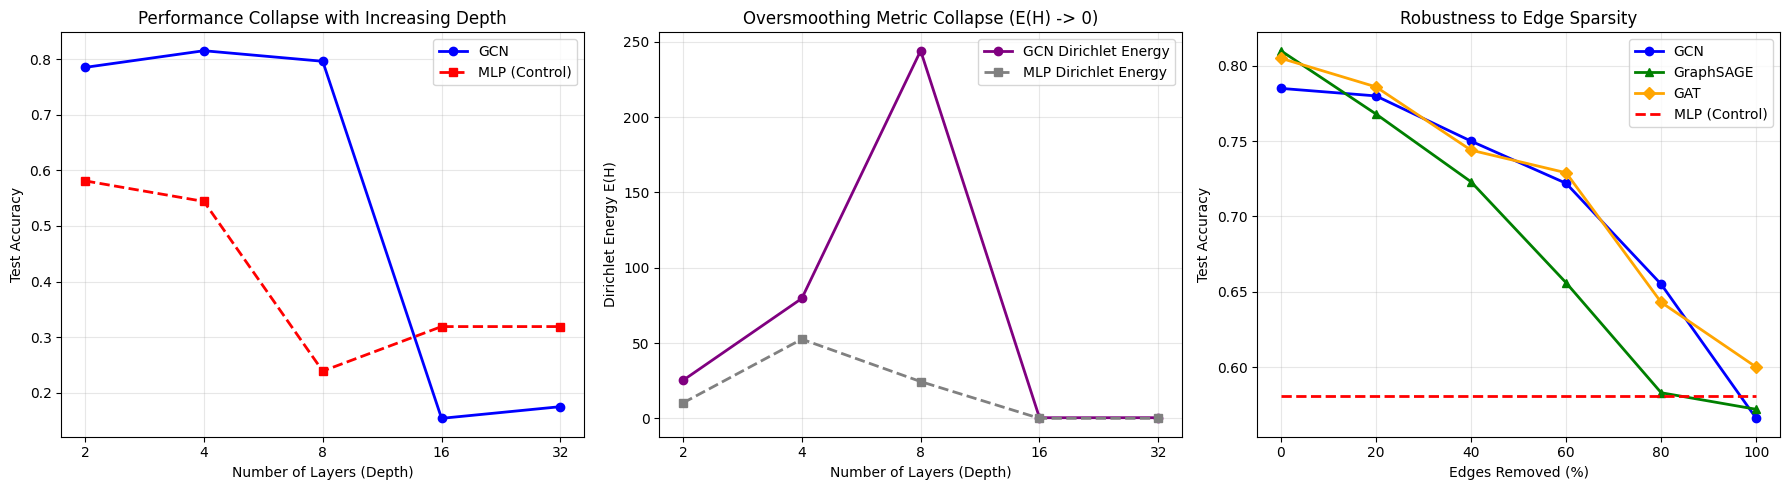

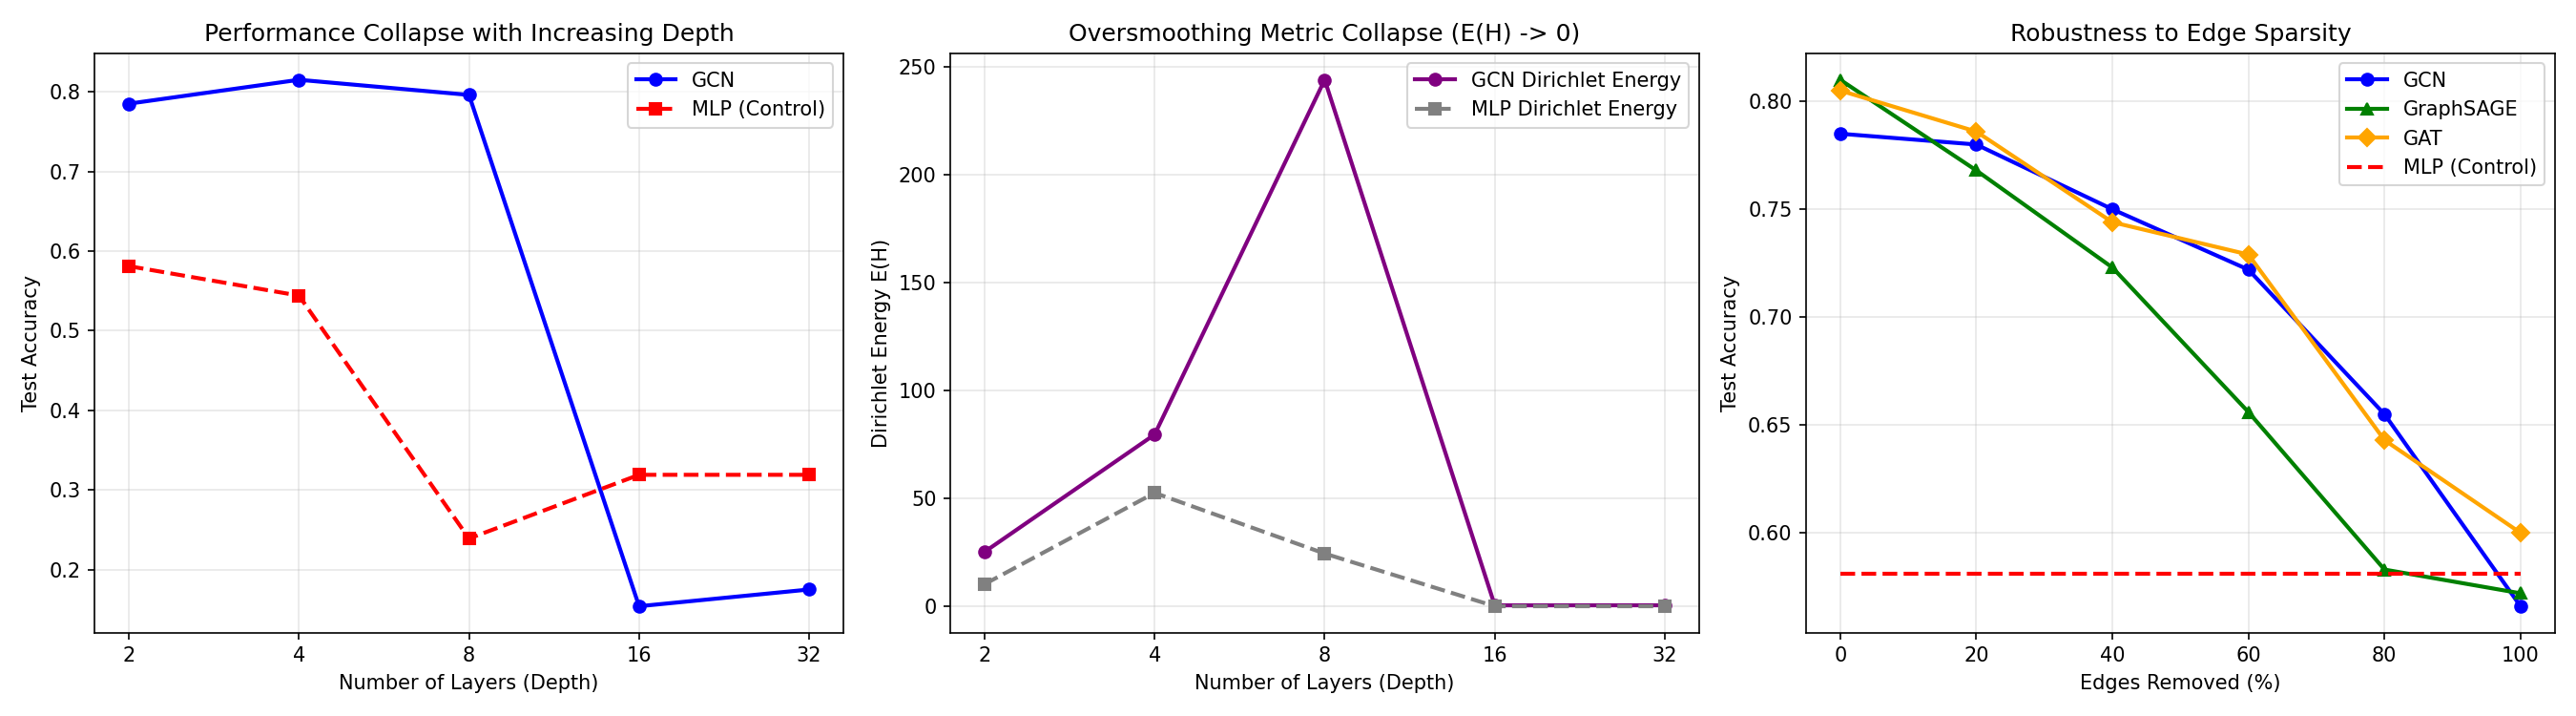


Saved comparison plots to: assignments/assignment_2_results.png

[SUCCESS] Assignment 2 execution completed successfully!


In [23]:
# CELL 9: VISUALIZATION - 3-PANEL DIAGNOSTIC PLOTS & COLAB DISPLAY
# Generates a 3-panel figure:
# Panel A: Test accuracy collapse with increasing depth (GCN vs MLP).
# Panel B: Dirichlet Energy decay quantifying oversmoothing.
# Panel C: Model robustness across varying edge sparsity levels.
# Saves assignment_2_results.png and displays it directly inline inside Colab.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Accuracy vs Depth
axes[0].plot(depths, gcn_accs, marker="o", color="blue", lw=2, label="GCN")
axes[0].plot(depths, mlp_accs, marker="s", color="red", linestyle="--", lw=2, label="MLP (Control)")
axes[0].set_xlabel("Number of Layers (Depth)")
axes[0].set_ylabel("Test Accuracy")
axes[0].set_title("Performance Collapse with Increasing Depth")
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(depths)
axes[0].set_xticklabels([str(d) for d in depths])
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Plot B: Dirichlet Energy vs Depth (Oversmoothing)
axes[1].plot(depths, gcn_energies, marker="o", color="purple", lw=2, label="GCN Dirichlet Energy")
axes[1].plot(depths, mlp_energies, marker="s", color="gray", linestyle="--", lw=2, label="MLP Dirichlet Energy")
axes[1].set_xlabel("Number of Layers (Depth)")
axes[1].set_ylabel("Dirichlet Energy E(H)")
axes[1].set_title("Oversmoothing Metric Collapse (E(H) -> 0)")
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(depths)
axes[1].set_xticklabels([str(d) for d in depths])
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Plot C: Edge Sparsity
for model_name, color, marker in [("GCN", "blue", "o"), ("GraphSAGE", "green", "^"), ("GAT", "orange", "D"), ("MLP", "red", "--")]:
    if model_name == "MLP":
        axes[2].plot([p * 100 for p in drop_pcts], sparsity_results[model_name], color=color, linestyle="--", lw=2, label="MLP (Control)")
    else:
        axes[2].plot([p * 100 for p in drop_pcts], sparsity_results[model_name], color=color, marker=marker, lw=2, label=model_name)
axes[2].set_xlabel("Edges Removed (%)")
axes[2].set_ylabel("Test Accuracy")
axes[2].set_title("Robustness to Edge Sparsity")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
output_dir = "assignments"
os.makedirs(output_dir, exist_ok=True)
output_plot = os.path.join(output_dir, "assignment_2_results.png")
plt.savefig(output_plot, dpi=150)
try:
    plt.show()
except Exception:
    pass

try:
    from IPython.display import Image, display
    display(Image(output_plot))
except Exception:
    pass

plt.close()
print(f"\nSaved comparison plots to: {output_plot}")
print("\n[SUCCESS] Assignment 2 execution completed successfully!")
